# 02 · Quem é visto por quais sensores?  🟢→🟡 *fácil a médio*

Agora a pergunta central da série: **o que os sensores têm em comum?** Se um IP aparece em todos os sensores,
provavelmente varre a internet inteira. Se aparece em um só, pode ser um visitante ocasional — ou alguém
interessado **naquele** pedaço da rede.

**Perguntas deste notebook**

1. Em quantos sensores cada origem aparece? (**cobertura**)
2. Quão parecidos são os conjuntos de origens de dois sensores? (**Jaccard**, **P(B|A)**, **lift**)
3. Que **combinações** de sensores são mais comuns? Há afinidade regional (Brasil × Itália)?
4. O que muda ao trocar **IP → /24 → ASN → país**? E ao juntar workers do mesmo **site**?

**Conceitos novos:** conjuntos, interseção, matriz de presença, modelo nulo.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

In [2]:
df = hio.carregar_holoscope(PASTA, extras=("asn", "geo"))
flags = hio.flags_texto(df["tcp_flags"])
df = df[~flags.isin(["SA", "R", "RA"])]       # só VARREDURA: backscatter vem das vítimas (notebook 06)
df = ha.adicionar_entidades(df)
SENS = sorted(df["sensor"].unique())
COR = ha.cores(SENS)
print(f"{len(df):,} pacotes de varredura")

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 105 MB na memória
origens reservadas/privadas descartadas: 35,000
1,908,199 pacotes de varredura


## 1. Entidades: em que nível olhar?

Uma **entidade** é "quem" estamos contando. Usaremos quatro níveis, do mais fino ao mais grosso:

| nível | coluna | exemplo | ideia |
|---|---|---|---|
| IP | `ent_ip` | 45.83.12.7 | uma máquina |
| /24 | `ent_24` | 45.83.12.0/24 | um bloco de 256 endereços (geralmente o mesmo dono) |
| ASN | `ent_asn` | AS65400 | uma organização/rede |
| País | `ent_pais` | DE | onde o IP está registrado |

`ha.adicionar_entidades` cria essas colunas (IP e /24 ficam como números, que é mais leve).

In [3]:
df[["ent_ip", "ent_24", "ent_asn", "ent_pais"]].nunique().rename("entidades distintas").to_frame()

,entidades distintas
ent_ip,35692
ent_24,14813
ent_asn,452
ent_pais,22


## 2. Matriz de presença e cobertura

A **matriz de presença** tem uma linha por entidade e uma coluna por sensor: `True` se a entidade foi vista ali.
Tudo deste notebook sai dela.

In [4]:
P = ha.matriz_presenca(df, "ent_ip")
P.head().set_axis(ha.rotulo("IP", P.index[:5]))

sensor,azure-worker-00,ifes-worker-00,polimi-worker-00,polimi-worker-01,polito-worker-00,ufes-worker-00
12.13.0.35,False,False,False,False,True,False
12.13.3.146,False,False,True,False,False,False
12.13.3.242,False,False,False,True,False,False
12.13.5.92,False,False,False,False,False,True
12.13.5.117,True,False,False,False,False,False


In [5]:
cobertura = P.sum(axis=1)               # em quantos sensores cada IP apareceu
pac_ip = df.groupby("ent_ip").size()     # pacotes por IP

tab = pd.DataFrame({"IPs": cobertura.value_counts().sort_index()})
tab["% dos IPs"] = (tab["IPs"] / tab["IPs"].sum() * 100).round(1)
tab["% dos pacotes"] = (pac_ip.groupby(cobertura).sum() / pac_ip.sum() * 100).round(1)
tab.index.name = "nº de sensores"
tab

,IPs,% dos IPs,% dos pacotes
nº de sensores,,,
1,26683,74.8,14.7
2,6168,17.3,22.0
3,199,0.6,0.1
4,199,0.6,0.1
5,210,0.6,0.1
6,2233,6.3,62.9


**Leitura:** a **maioria dos IPs** aparece em **um sensor só**, mas os poucos IPs vistos em **todos** os sensores
respondem por uma fatia **desproporcional** dos pacotes. "Quem é visto em todo lugar" é também "quem faz mais barulho".

Vamos repetir para os quatro níveis:

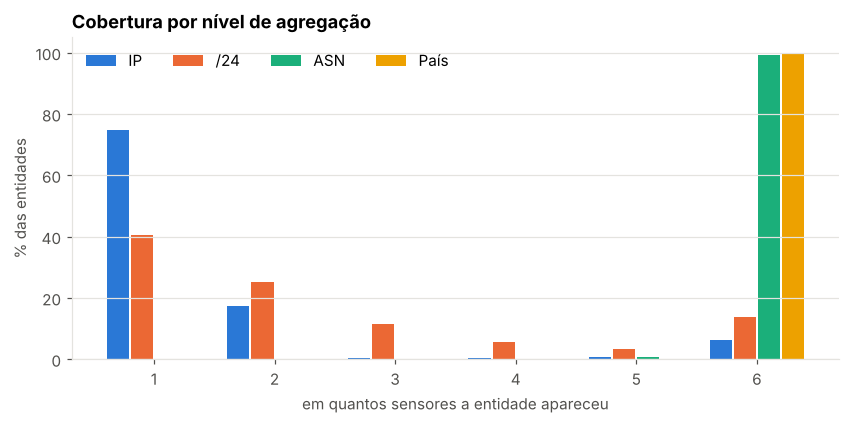

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
largura = 0.2
for k, (nome, col) in enumerate(ha.NIVEIS.items()):
    c = ha.matriz_presenca(df, col).sum(axis=1).value_counts(normalize=True).sort_index()
    c = c.reindex(range(1, len(SENS) + 1), fill_value=0)
    ax.bar(c.index + (k - 1.5) * largura, c.values * 100, width=largura * 0.92, label=nome, color=ha.PALETA[k])
ax.set_xlabel("em quantos sensores a entidade apareceu")
ax.set_ylabel("% das entidades")
ax.set_title("Cobertura por nível de agregação")
ax.legend(ncol=4)
ax.grid(axis="x", visible=False)
plt.show()

Quanto **mais grosso** o nível, mais entidades aparecem em **todos** os sensores. Parece uma descoberta
("as redes atacam todo mundo!"), mas parte disso é **mecânica**: um ASN com 500 IPs tem 500 chances de
aparecer em cada sensor. Na seção 5 testamos isso com um **modelo nulo**.

## 3. Semelhança entre pares de sensores

Três medidas, cada uma responde uma pergunta diferente:

* **Jaccard(A,B)** $= \dfrac{|A \cap B|}{|A \cup B|}$ — "quanto os conjuntos se sobrepõem?" (0 a 1, simétrico)
* **P(B | A)** $= \dfrac{|A \cap B|}{|A|}$ — "dos que vi em A, quantos também foram vistos em B?" (assimétrico)
* **lift(A,B)** $= \dfrac{P(A \cap B)}{P(A)\,P(B)}$ — "aparecem juntos mais que o acaso?" (1 = independência)

O Jaccard, por exemplo, é só uma multiplicação de matrizes. A função `ha.jaccard` faz isto:
```python
X = P.astype(int).values          # entidades x sensores, 0/1
inter = X.T @ X                    # inter[i, j] = nº de entidades vistas em i E em j
tam = diag(inter)                  # tamanho de cada conjunto
uniao = tam[i] + tam[j] - inter
jaccard = inter / uniao
```

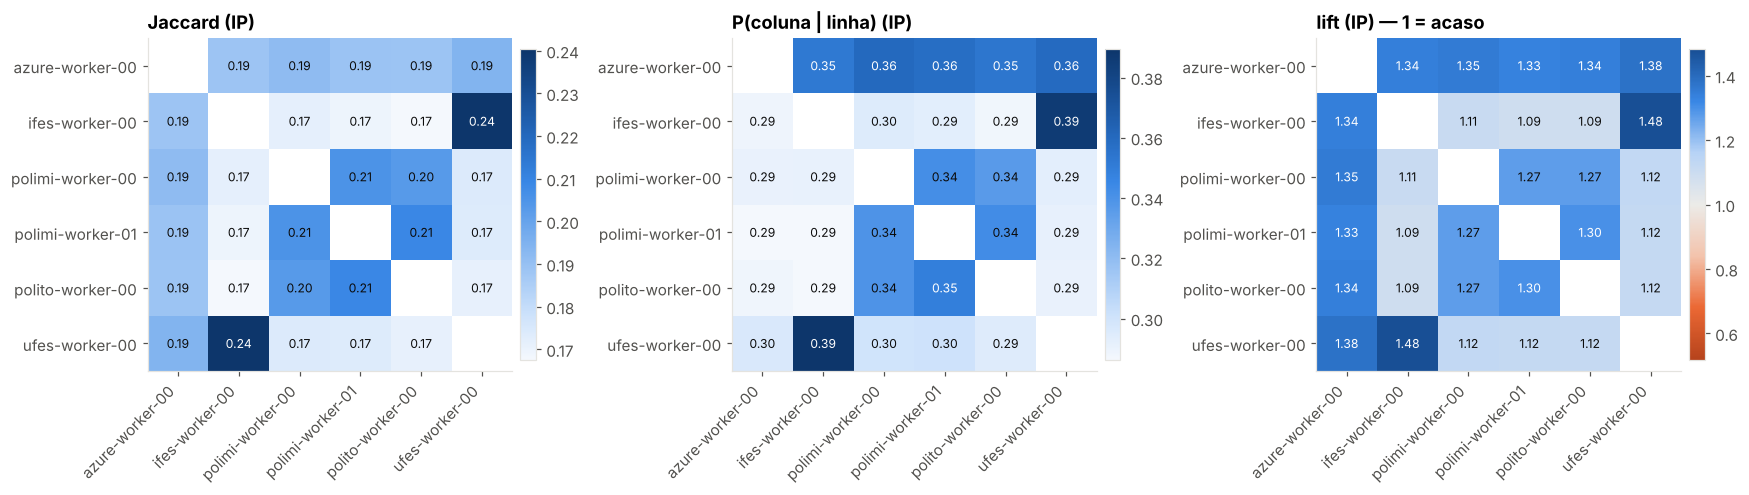

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
J = ha.jaccard(P)
C = ha.condicional(P)
L = ha.lift(P)
# a diagonal (sensor x ele mesmo) vira NaN para não dominar a escala de cores
ha.heatmap(ha.sem_diagonal(J), ax=axs[0], titulo="Jaccard (IP)")
ha.heatmap(ha.sem_diagonal(C), ax=axs[1], titulo="P(coluna | linha) (IP)")
ha.heatmap(ha.sem_diagonal(L), ax=axs[2], centro=1.0, titulo="lift (IP) — 1 = acaso")
plt.tight_layout(); plt.show()

**Como ler:**

* No **Jaccard**, procure blocos mais escuros: os pares **ufes/ifes** (Brasil) e **polimi/polito** (Itália)
  se parecem mais entre si do que com sensores de outra região → **afinidade regional**.
* No **lift**, valores **acima de 1** (azul) confirmam: esses pares aparecem juntos **mais do que o acaso** explicaria.
* A diagonal (cada sensor contra ele mesmo) foi apagada com `ha.sem_diagonal`: ela vale sempre 1 no Jaccard e
  em P(B|A) e só atrapalharia a escala de cores.

> ⚠️ **Armadilha:** Jaccard depende do **tamanho** dos conjuntos. Um sensor com muito menos IPs (ex.: um que ficou
> fora do ar alguns dias) terá Jaccard menor com todos, sem que isso diga algo sobre "afinidade". Use P(B|A) e lift
> para separar os efeitos.

### ✏️ TODO 1 — Jaccard no nível /24

Calcule a matriz de Jaccard no nível **/24** e guarde em `resp_1`. Desenhe-a ao lado da de IP.
Os valores sobem ou descem? Por quê?

<details><summary><b>Dica</b> (clique)</summary>

Troque `"ent_ip"` por `"ent_24"` em `ha.matriz_presenca` e chame `ha.jaccard`.

</details>

In [8]:
resp_1 = None   # TODO

In [9]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert resp_1.shape == (len(SENS), len(SENS)) and np.allclose(np.diag(resp_1), 1)
    assert np.allclose(resp_1.values, resp_1.values.T), "Jaccard é simétrico"
    print("✅ TODO 1 ok — média fora da diagonal:",
          f"IP {J.values[~np.eye(len(SENS), dtype=bool)].mean():.2f} | "
          f"/24 {resp_1.values[~np.eye(len(SENS), dtype=bool)].mean():.2f}")

⏳ TODO 1 ainda não resolvido


## 4. Combinações exatas: o gráfico "UpSet"

Com 6 sensores há $2^6 - 1 = 63$ combinações possíveis. Um diagrama de Venn com 6 conjuntos é ilegível;
o gráfico **UpSet** resolve: cada barra é uma **combinação exata**, e os pontos embaixo dizem quais sensores
a formam.

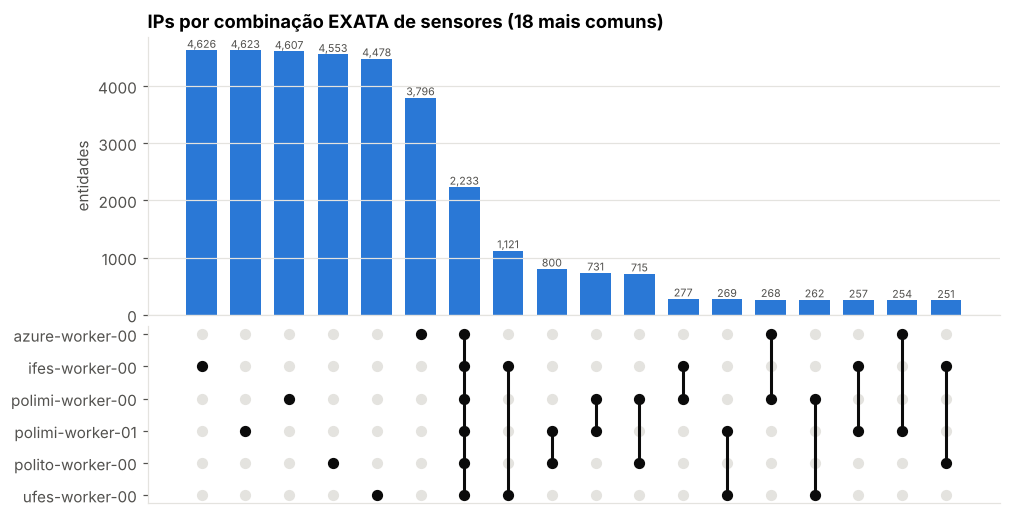

In [10]:
comb = ha.combinacoes(P, top=18)
ha.grafico_upset(comb, SENS, titulo="IPs por combinação EXATA de sensores (18 mais comuns)")
plt.show()

**Leitura:** depois das barras de "um sensor só", aparecem combinações como **todos os 6** e os **pares da mesma
região**. Combinações "estranhas" (ex.: um sensor brasileiro + um italiano, sem os outros) são raras.

### ✏️ TODO 2 — Os onipresentes

Quantos IPs foram vistos em **todos** os sensores, e que **fração dos pacotes de varredura** eles geraram?
Guarde em `resp_2 = (n_ips, fracao)`.

<details><summary><b>Dica</b> (clique)</summary>

`P.all(axis=1)` dá uma máscara booleana por IP. Use os índices `True` para filtrar `pac_ip`.

</details>

In [11]:
resp_2 = None   # TODO

In [12]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    n, f = resp_2
    assert n == (cobertura == len(SENS)).sum(), "confira o número de IPs"
    assert 0 < f < 1
    print("✅ TODO 2 ok")

⏳ TODO 2 ainda não resolvido


### ✏️ TODO 3 — Afinidade por país de origem

Para cada **país de origem**, calcule a fração dos seus IPs que foi vista **só** em sensores **brasileiros**
(`ufes-worker-00`, `ifes-worker-00`) e a fração vista **só** em sensores **italianos** (`polimi-*`, `polito-*`).
Guarde em `resp_3` um `DataFrame` com colunas `so_BR`, `so_IT` e `ips`, para os países com **≥ 500 IPs**.
Os IPs brasileiros preferem sensores brasileiros?

> Atenção: compare as **linhas** (países) entre si, não as colunas `so_BR` × `so_IT` — há 3 workers italianos e
> só 2 brasileiros, então `so_IT` tende a ser maior para **todo** país. A pergunta é: o Brasil está acima dos
> outros países em `so_BR`? A Itália e a Europa, em `so_IT`?

<details><summary><b>Dica</b> (clique)</summary>

1. País de cada IP: `df.groupby("ent_ip")["ent_pais"].first()`.
2. `so_BR` = IP visto em algum sensor BR **e** em nenhum fora: `P[BR].any(axis=1) & ~P[outros].any(axis=1)`.
3. Agrupe essas máscaras pelo país e tire a média.

</details>

In [13]:
resp_3 = None   # TODO

In [14]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    assert {"so_BR", "so_IT", "ips"} <= set(resp_3.columns) and (resp_3["ips"] >= 500).all()
    assert resp_3[["so_BR", "so_IT"]].stack().between(0, 1).all()
    print("✅ TODO 3 ok — compare as linhas BR e IT com as demais!")

⏳ TODO 3 ainda não resolvido


## 5. Agregar cria sobreposição "de graça"? Um modelo nulo

Vimos que, no nível /24, a cobertura sobe. Isso significa que **redes inteiras** coordenam varreduras? Ou é só
porque juntar IPs aumenta a chance de "acertar" mais sensores?

**Modelo nulo:** mantemos o tamanho de cada /24 (nº de IPs) e a cobertura de cada IP, mas **embaralhamos
qual IP pertence a qual /24**. Se a cobertura das /24 embaralhadas for **igual** à real, o aumento é só efeito
mecânico da agregação. Se a real for **maior**, há estrutura de verdade (IPs da mesma rede agindo juntos).

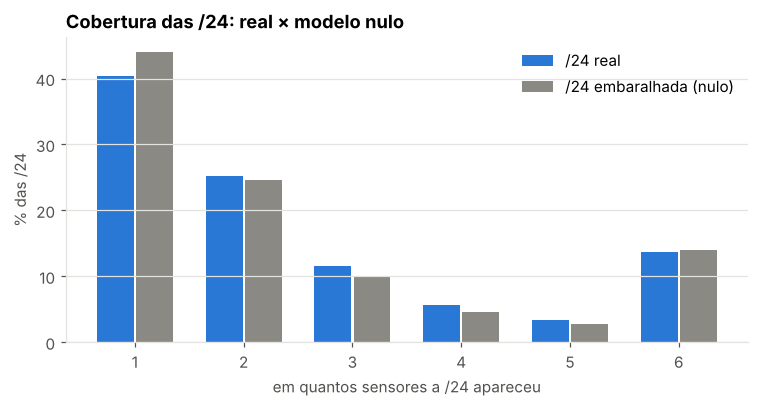

,1,2,3,4,5,6
real,40.5,25.2,11.6,5.6,3.4,13.7
nulo (média de 20),44.1,24.5,10.0,4.6,2.7,14.1


In [15]:
rng = np.random.default_rng(0)
ip24 = df.groupby("ent_ip")["ent_24"].first().reindex(P.index)

def cobertura_24(rotulos):
    """Cobertura das /24 quando cada IP recebe o rótulo de /24 em `rotulos`."""
    return P.groupby(rotulos.values).any().sum(axis=1)

real = cobertura_24(ip24)
nulos = [cobertura_24(pd.Series(rng.permutation(ip24.values), index=ip24.index)) for _ in range(20)]

dist = pd.DataFrame({"real": real.value_counts(normalize=True)}).sort_index()
dist["nulo (média de 20)"] = pd.concat([n.value_counts(normalize=True) for n in nulos], axis=1).mean(axis=1)
dist = dist.fillna(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = dist.index.values
ax.bar(x - 0.18, dist["real"] * 100, width=0.34, label="/24 real", color=ha.PALETA[0])
ax.bar(x + 0.18, dist["nulo (média de 20)"] * 100, width=0.34, label="/24 embaralhada (nulo)", color=ha.CINZA)
ax.set_xlabel("em quantos sensores a /24 apareceu"); ax.set_ylabel("% das /24")
ax.set_title("Cobertura das /24: real × modelo nulo"); ax.legend(); ax.grid(axis="x", visible=False)
plt.show()
(dist * 100).round(1).T

**Leitura:** se as barras real e nula são quase iguais, **agregar IP → /24 não prova coordenação**: a subida
da cobertura é efeito do tamanho das redes. Diferenças onde as barras divergem são as que merecem investigação
(no notebook 06 procuramos **"pools"**: redes cujos IPs dividem o trabalho entre sensores).

> 📌 Lição geral: **toda vez que um número "parece interessante", pergunte qual seria o valor ao acaso.**

## 6. Worker ou site?

Os dois workers do Polimi (`polimi-worker-00` e `-01`) são **blocos vizinhos** na mesma instituição. Devem ser
tratados como **um** sensor ou como **dois**? Olhe o Jaccard entre eles comparado aos outros pares.

In [16]:
par = J.loc["polimi-worker-00", "polimi-worker-01"]
outros = J.values[~np.eye(len(SENS), dtype=bool)]
print(f"Jaccard entre os dois workers do Polimi: {par:.3f}")
print(f"Jaccard médio entre os demais pares:     {outros.mean():.3f}  (máx {outros.max():.3f})")

Jaccard entre os dois workers do Polimi: 0.205
Jaccard médio entre os demais pares:     0.189  (máx 0.240)


### ✏️ TODO 4 — Refazer a cobertura por site

Carregue os dados com `unidade="site"`, remova o backscatter e crie as entidades, como no início.
Calcule em `resp_4` a **distribuição de cobertura** dos IPs (fração de IPs vistos em 1, 2, … sites).
Compare com a tabela da seção 2: a fração de IPs vistos em **todos** mudou? Por quê?

<details><summary><b>Dica</b> (clique)</summary>

`hio.carregar_holoscope(PASTA, extras=(), unidade="site", verbose=False)`; depois
`ha.matriz_presenca(d, "ent_ip").sum(axis=1).value_counts(normalize=True).sort_index()`.

</details>

In [17]:
resp_4 = None   # TODO

In [18]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert abs(resp_4.sum() - 1) < 1e-9 and resp_4.index.max() <= 5
    print("✅ TODO 4 ok")

⏳ TODO 4 ainda não resolvido


## Resumo

* A **matriz de presença** (entidade × sensor) é a base de todas as medidas de interseção.
* A maioria das origens aparece em **um** sensor, mas as que aparecem em **todos** dominam o volume.
* **Jaccard**, **P(B|A)** e **lift** respondem perguntas diferentes; o lift compara com o **acaso**.
* Há **afinidade regional** (pares BR–BR e IT–IT).
* Agregar (IP → /24 → ASN) aumenta a cobertura **mecanicamente**: teste com um **modelo nulo** antes de concluir.

## Desafios (sem solução)

1. **Intervalos de confiança.** Reamostre os IPs com reposição (*bootstrap*, 200 vezes) e calcule um intervalo de
   95% para o Jaccard de cada par. As diferenças entre pares são maiores que a incerteza?
2. **Janela de tempo.** Refaça a cobertura usando só 1 dia, depois 3, 7 e 14 dias. Como a fração de IPs em
   ≥ 2 sensores muda com a janela? E no nível ASN? (Dica: as curvas vão em direções opostas.)
3. **Por porta.** A afinidade regional é igual para todas as portas? Calcule o lift BR–BR só para IPs que buscam
   a porta 23 e só para a porta 22.
4. **ASN.** Faça o UpSet no nível **ASN**. Quais organizações estão em todos os sensores? Isso é surpresa?